# [GSE60495](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE60495)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2024-11-03
> - Modified: 2024-11-04

# 1. Experimental Design

> 	Genome-wide mapping of promoter-enhancer interactions with HiCap.
> - Sahlén, P., Abdullayev, I., Ramsköld, D. et al. Genome-wide mapping of promoter-anchored interactions with close to single-enhancer resolution. Genome Biol 16, 156 (2015). https://doi.org/10.1186/s13059-015-0727-9.
> - HiC
> - Illumina HiSeq 2000, PE100

| Sample | Cell | Source | Strain | Genotype | Replicate |
| - | - | - | - | - | - |
| mESC | ESC | Embryonic stem cells | R1 | Wild Type | rep1~2 |

In [1]:
options(scipen = 999)

library(tidyverse)
suppressPackageStartupMessages(library(GENOVA))
suppressPackageStartupMessages(library(RColorBrewer))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [2]:
data_dir <- "~/dataset_2/bulk_omics/hic_Mm_mESC_GSE60495/02_output/03_hicpro"

gtf_file <- "~/reference/Mus_musculus/mm10/gencode.vM23.annotation.gtf"

In [3]:
centromeres <- read.table(
    "~/reference/Mus_musculus/mm10/ucsc/gap.txt", col.names = c(
        "bin", "chr", "start", "end", "ix", "n", "size", "type", "bridge")) |>
    filter(type == "centromere") |>
    select(chr, start, end)

head(centromeres)

,chr,start,end
,<chr>,<int>,<int>
1,chr1,110000,3000000
2,chr10,110000,3000000
3,chr11,110000,3000000
4,chr12,110000,3000000
5,chr13,110000,3000000
6,chr14,110000,3000000


# 2. Evaluate Library Quality

# 3. Genome-wide

## 1). Import Data

In [4]:
binning <- 1000000
# binning_str <- format(binning, scientific = FALSE)

In [ ]:
mesc_rep1_1MB <- load_contacts(
    signal_path = file.path(
        data_dir, "hic_results/matrix/mESC_HiC_rep1/iced",
        binning, paste0("mESC_HiC_rep1_", binning, "_iced.matrix")),
    indices_path = file.path(
        data_dir, "hic_results/matrix/mESC_HiC_rep1/raw",
        binning, paste0("mESC_HiC_rep1_", binning, "_abs.bed")),
    resolution = binning, sample_name = "mESC_HiC_rep1", colour = "#ff0000",
    centromeres = centromeres)

mesc_rep1_1MB

Reading data...



A GENOVA contacts object named 'mESC_HiC_rep1' at a resolution of 1 Mb.
Contains the following slots:
- MAT	:	Triplet format matrix containing 6511430 informative bins.
- IDX	:	2782 genomic indices in BED format.
- CHRS	:	A vector of 63 chromosome names.
- CENTROMERES:	Locations of 20 centromeres.
This object is assigned the colour 'black'
0 bins are masked.
Some chromosomes have been removed.
The data have not been Z-score normalised.
The original data were loaded in as balanced data.

In [ ]:
mesc_rep2_1MB <- load_contacts(
    signal_path = file.path(
        data_dir, "hic_results/matrix/mESC_HiC_rep2/iced",
        binning, paste0("mESC_HiC_rep2_", binning, "_iced.matrix")),
    indices_path = file.path(
        data_dir, "hic_results/matrix/mESC_HiC_rep2/raw",
        binning, paste0("mESC_HiC_rep2_", binning, "_abs.bed")),
    resolution = binning, sample_name = "mESC_HiC_rep2", colour = "#0000ff",
    centromeres = centromeres)

mesc_rep2_1MB

Reading data...



A GENOVA contacts object named 'mESC_HiC_rep2' at a resolution of 1 Mb.
Contains the following slots:
- MAT	:	Triplet format matrix containing 6123452 informative bins.
- IDX	:	2782 genomic indices in BED format.
- CHRS	:	A vector of 63 chromosome names.
- CENTROMERES:	Locations of 20 centromeres.
This object is assigned the colour 'black'
0 bins are masked.
Some chromosomes have been removed.
The data have not been Z-score normalised.
The original data were loaded in as balanced data.

## 2). Cis-quantification

In [7]:
cisChrom_out <- list(mesc_rep1_1MB, mesc_rep2_1MB) |> cis_trans()

cisChrom_out

sample,cis,region
<chr>,<dbl>,<chr>
mESC_HiC_rep1,61.11585,genome-wide
mESC_HiC_rep2,64.88938,genome-wide


## 3). Chromosome plots

# 4. A/B Compartments

In [12]:
binning <- 100000

mesc_rep1_100kb <- load_contacts(
    signal_path = file.path(
        data_dir, "hic_results/matrix/mESC_HiC_rep1/iced",
        binning, paste0("mESC_HiC_rep1_", binning, "_iced.matrix")),
    indices_path = file.path(
        data_dir, "hic_results/matrix/mESC_HiC_rep1/raw",
        binning, paste0("mESC_HiC_rep1_", binning, "_abs.bed")),
    resolution = binning, sample_name = "mESC_HiC_rep1", colour = "#ff0000",
    centromeres = centromeres, verbose = FALSE)

mesc_rep2_100kb <- load_contacts(
    signal_path = file.path(
        data_dir, "hic_results/matrix/mESC_HiC_rep2/iced",
        binning, paste0("mESC_HiC_rep2_", binning, "_iced.matrix")),
    indices_path = file.path(
        data_dir, "hic_results/matrix/mESC_HiC_rep2/raw",
        binning, paste0("mESC_HiC_rep2_", binning, "_abs.bed")),
    resolution = binning, sample_name = "mESC_HiC_rep2", colour = "#0000ff",
    centromeres = centromeres, verbose = FALSE)

In [13]:
mesc_rep1_100kb

A GENOVA contacts object named 'mESC_HiC_rep1' at a resolution of 100 kb.
Contains the following slots:
- MAT	:	Triplet format matrix containing 45223482 informative bins.
- IDX	:	27348 genomic indices in BED format.
- CHRS	:	A vector of 49 chromosome names.
- CENTROMERES:	Locations of 20 centromeres.
This object is assigned the colour '#ff0000'
0 bins are masked.
Some chromosomes have been removed.
The data have not been Z-score normalised.
The original data were loaded in as balanced data.

## Analysis

In [45]:
CS_out <- compartment_score(list(mesc_rep1_100kb, mesc_rep2_100kb))

Warning message:
“Removed 62 rows containing missing values or values outside the scale range
(`geom_line()`).”


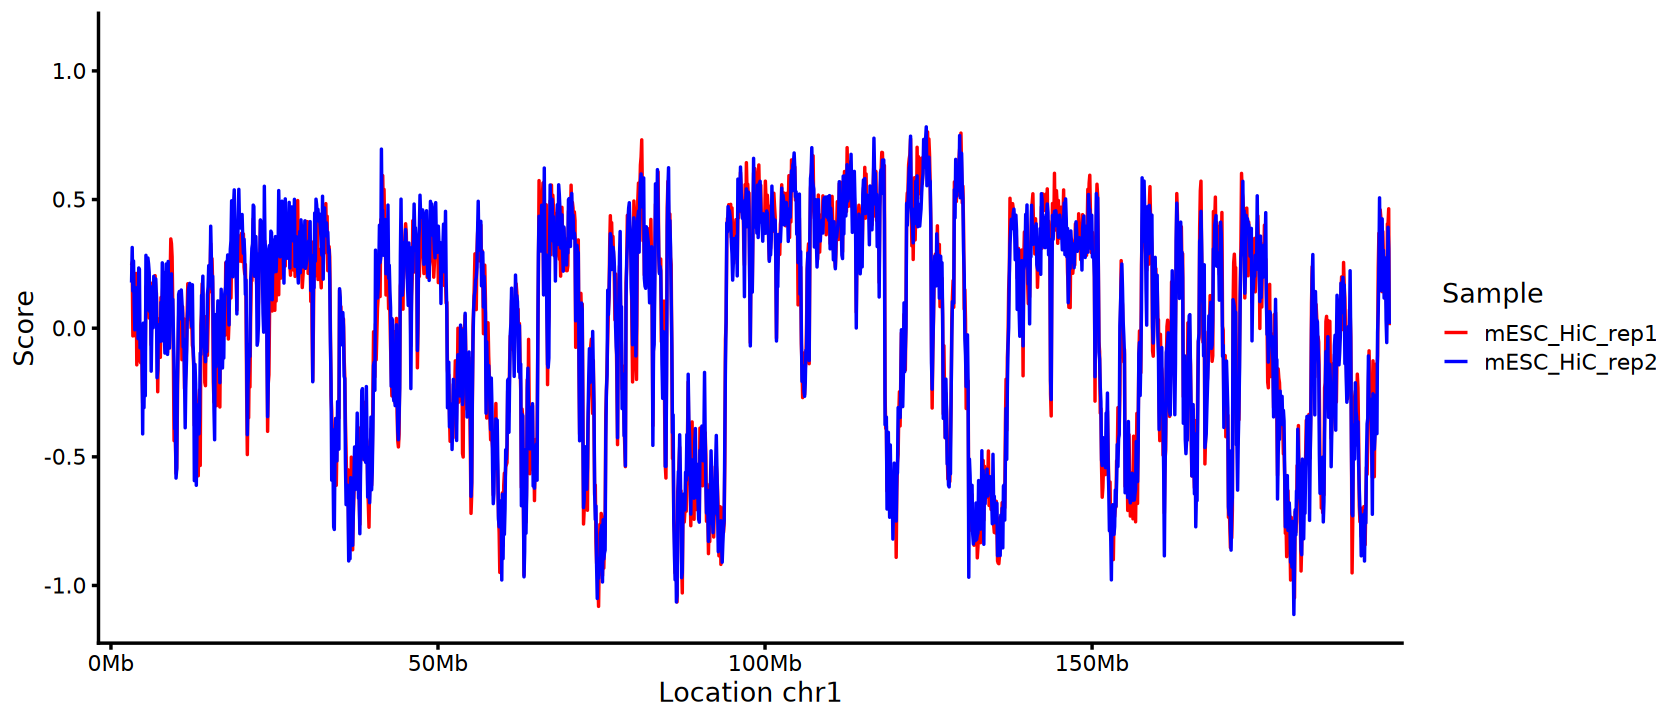

In [46]:
options(repr.plot.width = 14, repr.plot.height = 6)

visualise(CS_out, chr = "chr1") + theme_classic(base_size = 16)

In [47]:
mesc_h3k27ac <- file.path(
    "~/dataset_2/bulk_omics/chipseq_Mm_mESC_Histone_GSE120376", 
    "06_chipseq_output", "05_peaks", 
    "mESC_LIF_H3K27ac_peaks.narrowPeak") |>
    rtracklayer::import() |>
    BRGenomics::tidyChromosomes(
        keep.X = FALSE, keep.Y = FALSE, keep.M = FALSE) |>
    GenomicRanges::granges() |>
    as.data.frame() |>
    select(seqnames, start, end)

head(mesc_h3k27ac)

,seqnames,start,end
,<fct>,<int>,<int>
1,chr1,3062491,3062793
2,chr1,3343977,3344630
3,chr1,3482155,3482713
4,chr1,3483393,3483653
5,chr1,3852542,3852984
6,chr1,3982309,3983520


In [48]:
# CS_out <- list(mesc_rep1_100kb, mesc_rep2_100kb) |> 
#     compartment_score(bed = mesc_h3k27ac)
CS_out <- sign_compartmentscore(CS_out, bed = mesc_h3k27ac, ref = 1)

Warning message in wilcox.test.default(count[up], count[down]):
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(count[up], count[down]):
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(count[up], count[down]):
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(count[up], count[down]):
“cannot compute exact p-value with ties”


Warning message:
“Removed 62 rows containing missing values or values outside the scale range
(`geom_line()`).”


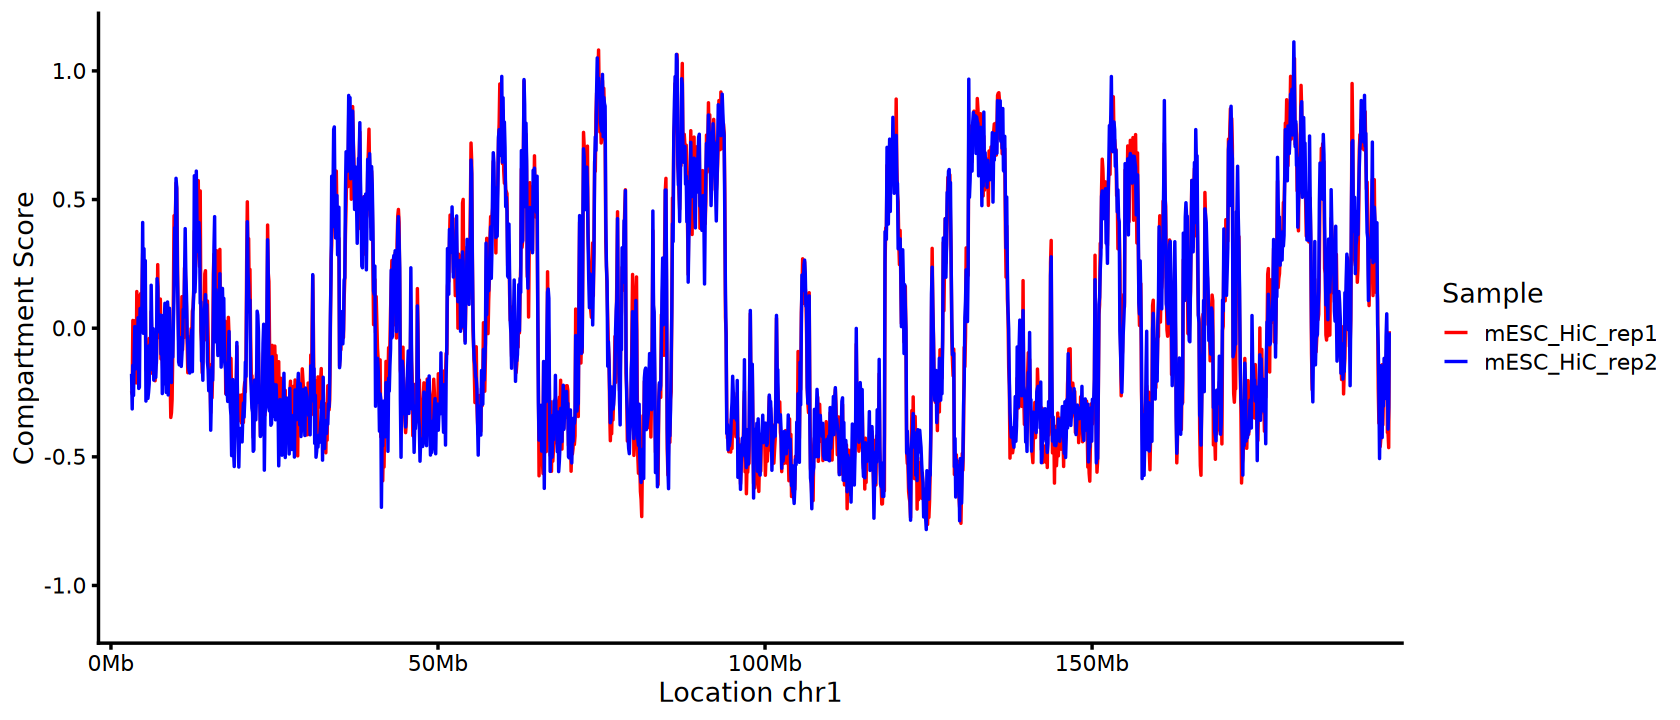

In [49]:
options(repr.plot.width = 14, repr.plot.height = 6)

visualise(CS_out, chr = "chr1") + theme_classic(base_size = 16)

In [50]:
cor(
    CS_out$compart_scores$mESC_HiC_rep1, 
    CS_out$compart_scores$mESC_HiC_rep2, 
    use = "complete.obs"
)

[1] 0.9602078

## Saddle

In [28]:
saddle_out <- list(mesc_rep1_100kb, mesc_rep2_100kb) |>
    saddle(CS_discovery = CS_out, bins = 50)

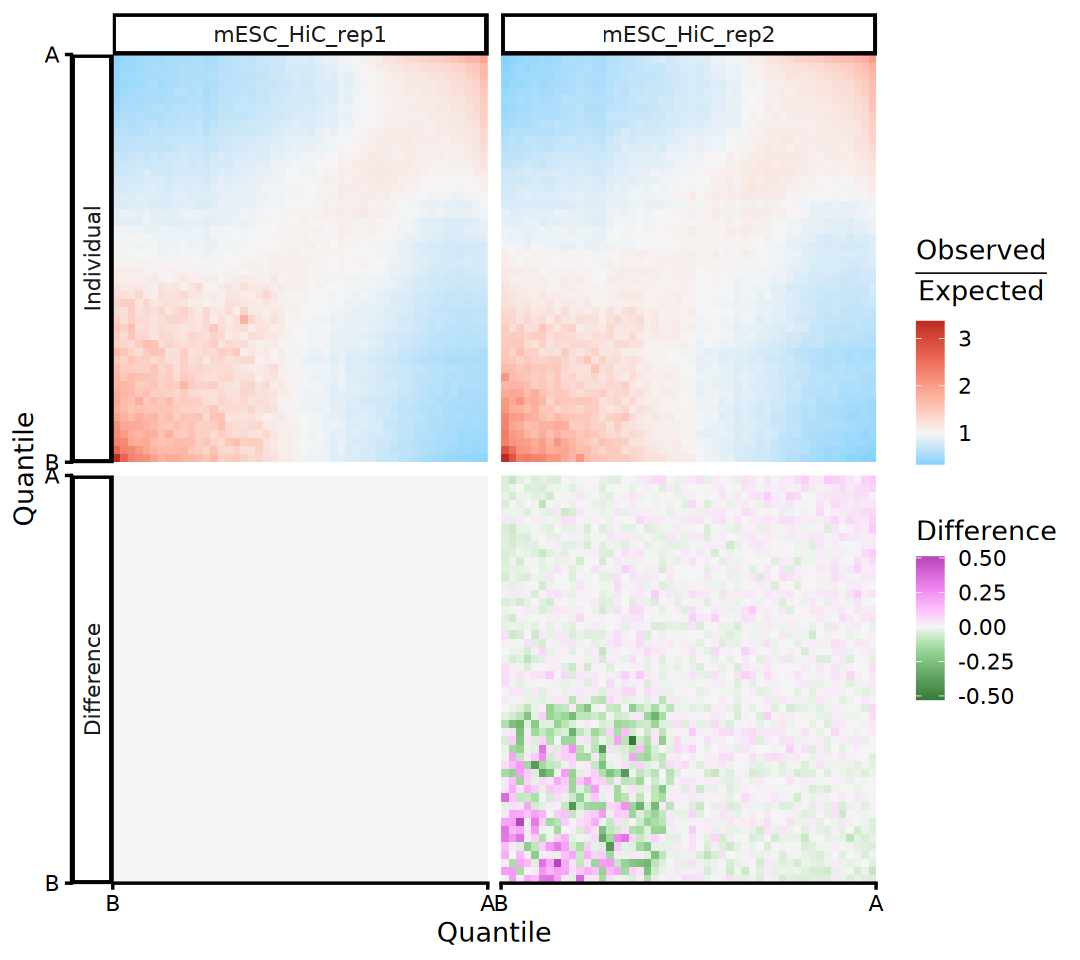

In [37]:
options(repr.plot.width = 9, repr.plot.height = 8)

visualise(saddle_out) + theme_classic(base_size = 16)

## Compartment-strength

In [38]:
CSS <- quantify(saddle_out)

In [41]:
compared <- tidyr::spread(
    unique(CSS[,-c(3,4)]), key = 'exp', value = 'strength')

head(compared)

,chr,mESC_HiC_rep1,mESC_HiC_rep2
,<chr>,<dbl>,<dbl>
1,chr10q,1.708904,1.821063
2,chr11q,1.949830,2.051652
3,chr12q,1.709389,1.787396
4,chr13q,1.412410,1.522737
5,chr14q,1.575481,1.783562
6,chr15q,1.679145,1.760536


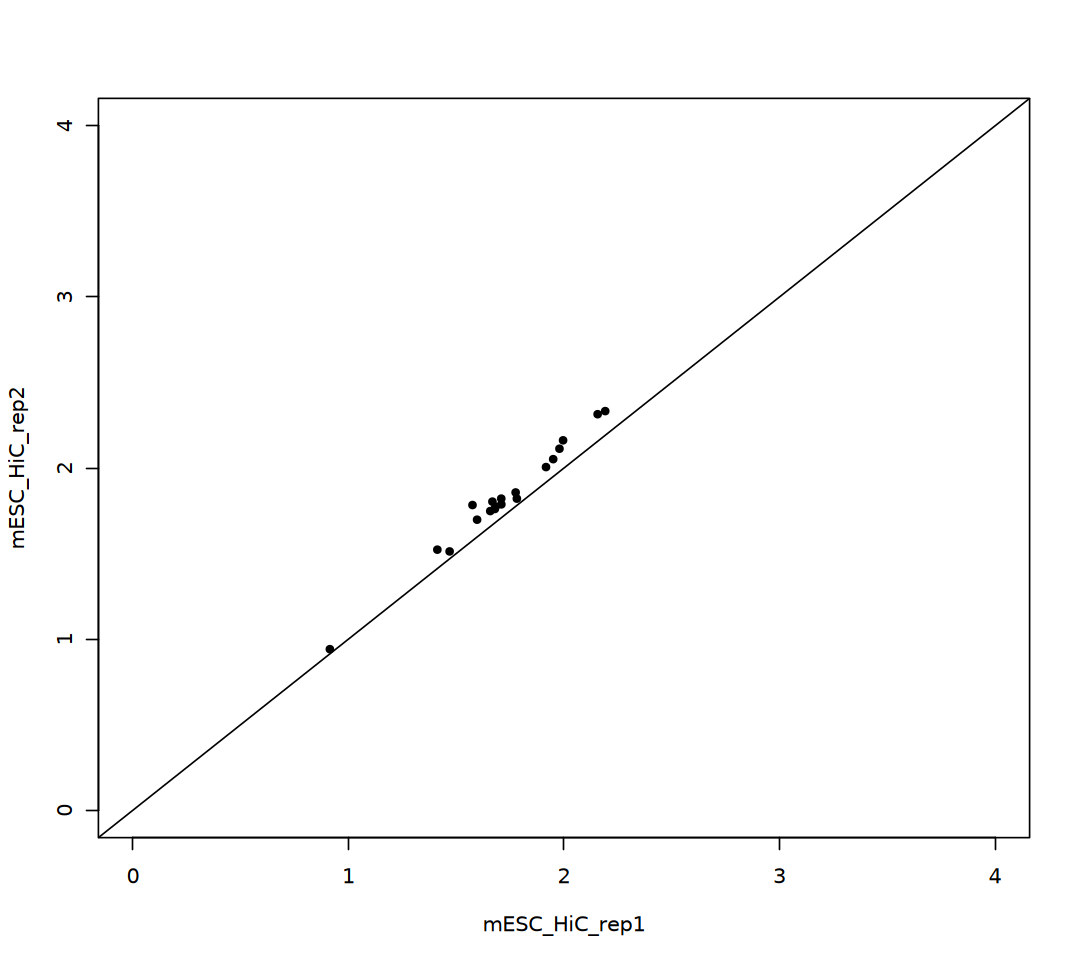

In [42]:
options(repr.plot.width = 9, repr.plot.height = 8)

with(compared, plot(
    mESC_HiC_rep1, mESC_HiC_rep2, 
    xlim = c(0,4), ylim = c(0,4), pch = 20))
abline(a = 0, b = 1, lty = 1)

In [ ]:
# options(repr.plot.width = 9, repr.plot.height = 8)

# compartment_matrixplot(
#     exp1 = mesc_rep1_100kb, exp2 = mesc_rep2_100kb,
#     CS_discovery = CS_out, chrom = "chr2", arm = "q",
#     metric = "contacts", colour_lim = c(0, 15))

Warning message in mat[i] <- dat$V3:
“number of items to replace is not a multiple of replacement length”


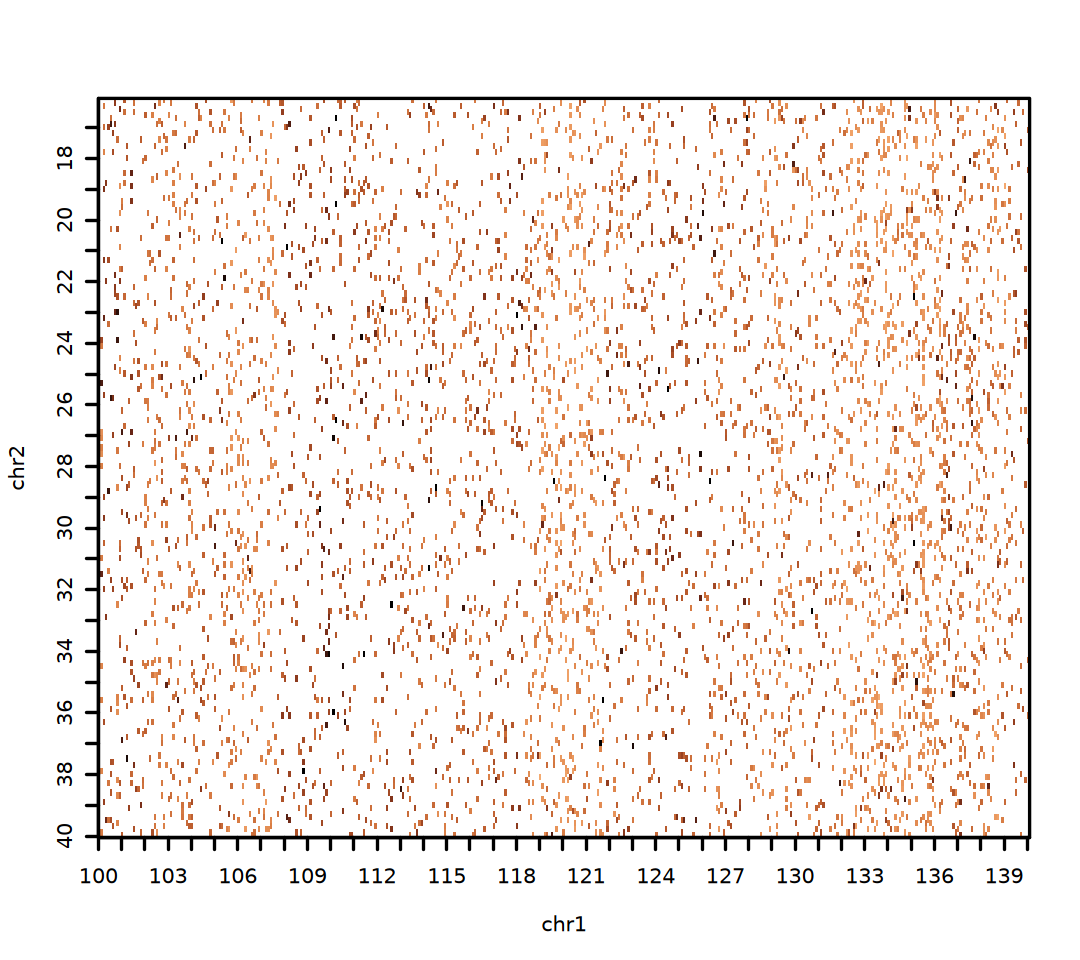

In [66]:
options(repr.plot.width = 9, repr.plot.height = 8)

trans_matrixplot(
    mesc_rep1_100kb, 
    chrom_up = "chr1", start_up = 100e6, end_up = 140e6,
    chrom_down = "chr2", start_down = 16e6, end_down = 40e6,
    colour_lim = c(0, 20))

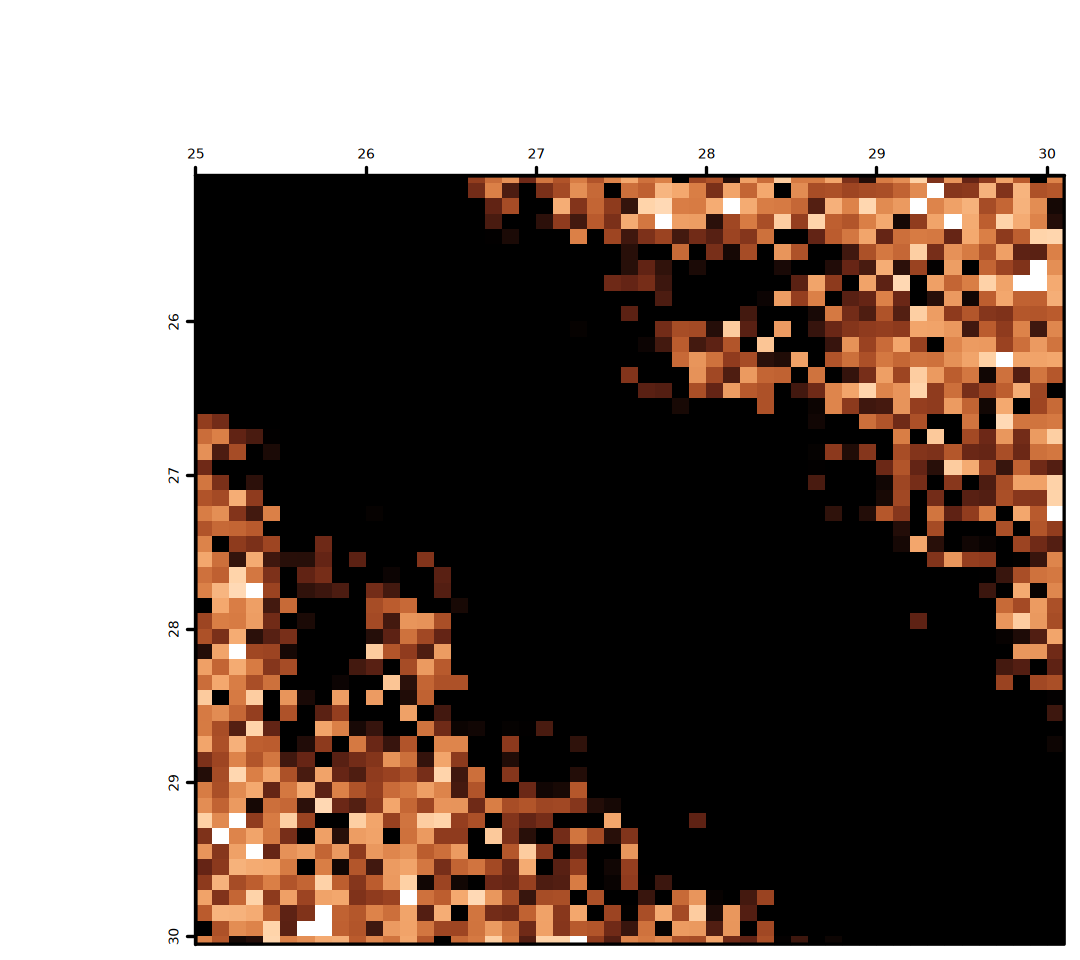

In [67]:
hic_matrixplot(
    exp1 = mesc_rep1_100kb, 
    chrom = 'chr2', start = 25e6, end=30e6, cut.off = 50)

# 5. TAD

> Topologically Associated Domains (TADs)

In [51]:
binning <- 40000

mesc_rep1_40kb <- load_contacts(
    signal_path = file.path(
        data_dir, "hic_results/matrix/mESC_HiC_rep1/iced",
        binning, paste0("mESC_HiC_rep1_", binning, "_iced.matrix")),
    indices_path = file.path(
        data_dir, "hic_results/matrix/mESC_HiC_rep1/raw",
        binning, paste0("mESC_HiC_rep1_", binning, "_abs.bed")),
    resolution = binning, sample_name = "mESC_HiC_rep1", colour = "#ff0000",
    centromeres = centromeres, verbose = FALSE)

mesc_rep2_40kb <- load_contacts(
    signal_path = file.path(
        data_dir, "hic_results/matrix/mESC_HiC_rep2/iced",
        binning, paste0("mESC_HiC_rep2_", binning, "_iced.matrix")),
    indices_path = file.path(
        data_dir, "hic_results/matrix/mESC_HiC_rep2/raw",
        binning, paste0("mESC_HiC_rep2_", binning, "_abs.bed")),
    resolution = binning, sample_name = "mESC_HiC_rep2", colour = "#0000ff",
    centromeres = centromeres, verbose = FALSE)

In [52]:
mesc_rep1_40kb

A GENOVA contacts object named 'mESC_HiC_rep1' at a resolution of 40 kb.
Contains the following slots:
- MAT	:	Triplet format matrix containing 56238879 informative bins.
- IDX	:	68301 genomic indices in BED format.
- CHRS	:	A vector of 36 chromosome names.
- CENTROMERES:	Locations of 20 centromeres.
This object is assigned the colour '#ff0000'
0 bins are masked.
Some chromosomes have been removed.
The data have not been Z-score normalised.
The original data were loaded in as balanced data.

In [18]:
RCP_out <- list(mesc_rep1_40kb, mesc_rep2_40kb) |> RCP(chromsToUse = 'chr1')

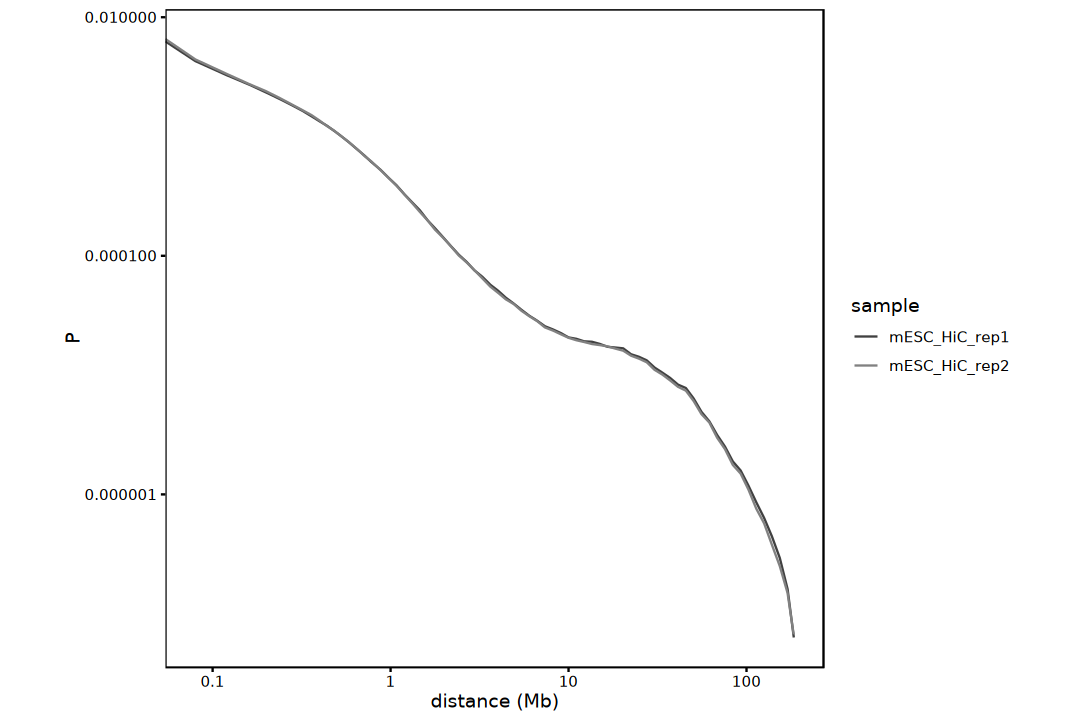

In [22]:
options(repr.plot.width = 9, repr.plot.height = 6)

visualise(RCP_out)

# 6. Loop